# Algoritmo de Floyd-Warshall

Calcula las distancias mínimas entre **todos los pares** de nodos con programación dinámica: para cada nodo intermedio $k$, $d_{ij} = \min(d_{ij}, d_{ik} + d_{kj})$. Admite pesos negativos (sin ciclos negativos) y cuesta $O(V^3)$.

## 1. Matriz de distancias

Calcular la matriz de distancias mínimas a partir de la matriz de pesos (`inf` = sin arista).

In [1]:
INF = float("inf")

pesos = [
    [0, 3, INF, 7],
    [8, 0, 2, INF],
    [5, INF, 0, 1],
    [2, INF, INF, 0],
]

def floyd_warshall(pesos):
    n = len(pesos)
    d = [fila[:] for fila in pesos]
    for k in range(n):
        for i in range(n):
            for j in range(n):
                d[i][j] = min(d[i][j], d[i][k] + d[k][j])
    return d

for fila in floyd_warshall(pesos):
    print(fila)

[0, 3, 5, 6]
[5, 0, 2, 3]
[3, 6, 0, 1]
[2, 5, 7, 0]


## 2. Caminos y ciclos negativos

Guardar el siguiente nodo de cada camino para reconstruirlo, y detectar ciclos negativos (alguna diagonal queda negativa).

In [2]:
def floyd_warshall_caminos(pesos):
    n = len(pesos)
    d = [fila[:] for fila in pesos]
    siguiente = [[j if pesos[i][j] < INF else None for j in range(n)] for i in range(n)]
    for k in range(n):
        for i in range(n):
            for j in range(n):
                if d[i][k] + d[k][j] < d[i][j]:
                    d[i][j] = d[i][k] + d[k][j]
                    siguiente[i][j] = siguiente[i][k]
    return d, siguiente

def camino(siguiente, i, j):
    if siguiente[i][j] is None:
        return None
    ruta = [i]
    while i != j:
        i = siguiente[i][j]
        ruta.append(i)
    return ruta

d, siguiente = floyd_warshall_caminos(pesos)
print(camino(siguiente, 1, 0), d[1][0])

d_neg, _ = floyd_warshall_caminos([[0, 1, INF], [INF, 0, -2], [-1, INF, 0]])
print("Ciclo negativo:", any(d_neg[i][i] < 0 for i in range(3)))

[1, 2, 3, 0] 5
Ciclo negativo: True


## 3. Cierre transitivo

Con booleanos, la misma triple iteración (algoritmo de Warshall) calcula qué nodos alcanzan a cuáles por un camino de al menos una arista: $a_{ij} \leftarrow a_{ij} \lor (a_{ik} \land a_{kj})$. La diagonal queda a `True` solo en los nodos que están en un ciclo. Aplicarlo a una red de vuelos directos inventada y comprobarlo con un BFS desde cada nodo en grafos aleatorios.

In [3]:
import random
from collections import deque

def warshall(adyacencia):
    n = len(adyacencia)
    a = [fila[:] for fila in adyacencia]
    for k in range(n):
        for i in range(n):
            if a[i][k]:
                for j in range(n):
                    a[i][j] = a[i][j] or a[k][j]
    return a

def alcanzables_bfs(adyacencia, i):
    n = len(adyacencia)
    vistos, cola = set(), deque(j for j in range(n) if adyacencia[i][j])
    vistos.update(cola)
    while cola:
        u = cola.popleft()
        for v in range(n):
            if adyacencia[u][v] and v not in vistos:
                vistos.add(v)
                cola.append(v)
    return [j in vistos for j in range(n)]

aeropuertos = ["LPA", "TFN", "ACE", "FUE", "MAD", "BCN"]
vuelos = [("TFN", "LPA"), ("LPA", "ACE"), ("ACE", "LPA"), ("LPA", "MAD"), ("FUE", "MAD"), ("MAD", "BCN"), ("BCN", "MAD")]
indice = {a: i for i, a in enumerate(aeropuertos)}
adyacencia = [[False] * len(aeropuertos) for _ in aeropuertos]
for u, v in vuelos:
    adyacencia[indice[u]][indice[v]] = True

alcanza = warshall(adyacencia)
print("     " + " ".join(aeropuertos))
for a, fila in zip(aeropuertos, alcanza):
    print(a, " ", "   ".join("X" if x else "." for x in fila))

random.seed(4)
for _ in range(300):
    n = random.randint(1, 8)
    ady = [[random.random() < 0.2 for _ in range(n)] for _ in range(n)]
    assert warshall(ady) == [alcanzables_bfs(ady, i) for i in range(n)]

     LPA TFN ACE FUE MAD BCN
LPA   X   .   X   .   X   X
TFN   X   .   X   .   X   X
ACE   X   .   X   .   X   X
FUE   .   .   .   .   X   X
MAD   .   .   .   .   X   X
BCN   .   .   .   .   X   X


## 4. Centro del grafo

La excentricidad de un nodo es la distancia al nodo más lejano, $e(v) = \max_u d(v, u)$. El **centro** es el nodo de menor excentricidad (dónde poner un parque de bomberos para que el peor caso sea lo más corto posible) y la **mediana**, el de menor suma de distancias (minimiza el recorrido medio). Calcularlos en una red de pueblos inventada, comprobar las distancias con Dijkstra desde cada nodo y dibujar la red.

Playa     excentricidad  45 km, suma  287 km
Puerto    excentricidad  49 km, suma  267 km
Barranco  excentricidad  49 km, suma  231 km
Ermita    excentricidad  62 km, suma  279 km
Llano     excentricidad  65 km, suma  239 km
Valle     excentricidad  67 km, suma  257 km
Cumbre    excentricidad  77 km, suma  264 km
Molino    excentricidad  77 km, suma  293 km
Aldea     excentricidad  79 km, suma  298 km
Faro      excentricidad  79 km, suma  559 km
Centro: Playa  mediana: Barranco


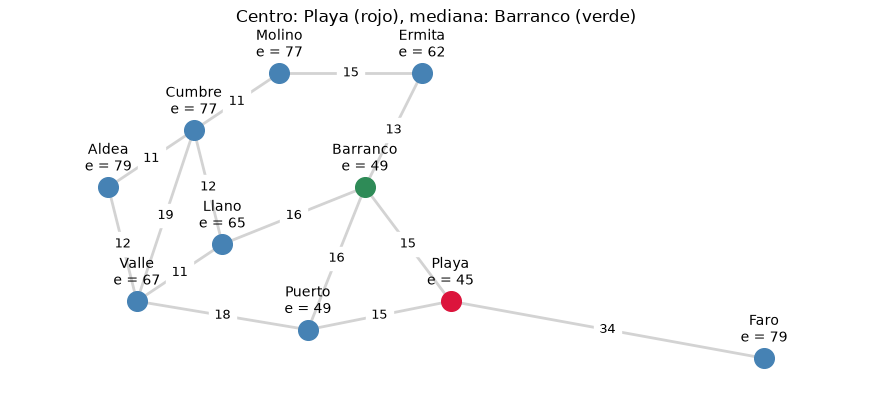

In [4]:
import heapq
from math import dist
import matplotlib.pyplot as plt

posiciones = {"Valle": (0, 0), "Puerto": (6, -1), "Cumbre": (2, 6), "Llano": (3, 2), "Barranco": (8, 4),
              "Playa": (11, 0), "Molino": (5, 8), "Ermita": (10, 8), "Aldea": (-1, 4), "Faro": (22, -2)}
carreteras = [("Valle", "Llano"), ("Valle", "Puerto"), ("Valle", "Cumbre"), ("Llano", "Cumbre"), ("Llano", "Barranco"),
              ("Puerto", "Barranco"), ("Puerto", "Playa"), ("Cumbre", "Molino"), ("Molino", "Ermita"),
              ("Barranco", "Ermita"), ("Barranco", "Playa"), ("Aldea", "Valle"), ("Aldea", "Cumbre"),
              ("Playa", "Faro")]
nombres = list(posiciones)
n = len(nombres)
indice = {p: i for i, p in enumerate(nombres)}
matriz = [[0 if i == j else INF for j in range(n)] for i in range(n)]
for u, v in carreteras:
    km = round(dist(posiciones[u], posiciones[v]) * 3)
    matriz[indice[u]][indice[v]] = matriz[indice[v]][indice[u]] = km
d = floyd_warshall(matriz)

def dijkstra(matriz, origen):
    distancia = [INF] * len(matriz)
    distancia[origen] = 0
    cola = [(0, origen)]
    while cola:
        du, u = heapq.heappop(cola)
        if du > distancia[u]:
            continue
        for v, w in enumerate(matriz[u]):
            if du + w < distancia[v]:
                distancia[v] = du + w
                heapq.heappush(cola, (distancia[v], v))
    return distancia

assert all(dijkstra(matriz, i) == d[i] for i in range(n))

excentricidad = [max(fila) for fila in d]
suma = [sum(fila) for fila in d]
centro = nombres[min(range(n), key=excentricidad.__getitem__)]
mediana = nombres[min(range(n), key=suma.__getitem__)]
for p, e, s in sorted(zip(nombres, excentricidad, suma), key=lambda x: x[1]):
    print(f"{p:<9} excentricidad {e:>3} km, suma {s:>4} km")
print("Centro:", centro, " mediana:", mediana)

fig, eje = plt.subplots(figsize=(11, 5))
for u, v in carreteras:
    (x1, y1), (x2, y2) = posiciones[u], posiciones[v]
    eje.plot([x1, x2], [y1, y2], color="lightgray", linewidth=2, zorder=1)
    eje.text((x1 + x2) / 2, (y1 + y2) / 2, matriz[indice[u]][indice[v]], ha="center", va="center", fontsize=9,
             backgroundcolor="white")
for p, (x, y) in posiciones.items():
    color = "crimson" if p == centro else "seagreen" if p == mediana else "steelblue"
    eje.scatter(x, y, s=200, color=color, zorder=2)
    eje.annotate(f"{p}\ne = {excentricidad[indice[p]]}", (x, y), xytext=(0, 12), textcoords="offset points",
                 ha="center")
eje.set_title(f"Centro: {centro} (rojo), mediana: {mediana} (verde)")
eje.margins(0.15)
eje.set_aspect("equal")
eje.axis("off")
plt.show()